In [2]:
%pip install pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
from PIL import Image
from collections import Counter

dataset_path = r"C:\Users\asus\ICD311_Shoe_Classifier\dataset\shoe-dataset"

train_path = os.path.join(dataset_path, "train")

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("SHOE DATASET INSPECTION - shoe_classifier.ipynb:11")
print("" * 40)

for category in sorted(os.listdir(train_path)):

    category_path = os.path.join(train_path, category)

    if not os.path.isdir(category_path):
        continue

    images = [
        f for f in os.listdir(category_path)
        if f.lower().endswith(image_extensions)
    ]

    print(f"\nCategory: {category} - shoe_classifier.ipynb:26")
    print(f"Number of images: {len(images)} - shoe_classifier.ipynb:27")

    if images:
        image_path = os.path.join(category_path, images[0])

        with Image.open(image_path) as img:
            print(f"Image dimensions: {img.size} - shoe_classifier.ipynb:33")
            print(f"Image mode: {img.mode} - shoe_classifier.ipynb:34")
            print(f"Image format: {img.format} - shoe_classifier.ipynb:35")

SHOE DATASET INSPECTION - shoe_classifier.ipynb:11


Category: ballet_flats - shoe_classifier.ipynb:26
Number of images: 600 - shoe_classifier.ipynb:27
Image dimensions: (225, 225) - shoe_classifier.ipynb:33
Image mode: RGB - shoe_classifier.ipynb:34
Image format: JPEG - shoe_classifier.ipynb:35

Category: boats - shoe_classifier.ipynb:26
Number of images: 600 - shoe_classifier.ipynb:27
Image dimensions: (300, 168) - shoe_classifier.ipynb:33
Image mode: RGB - shoe_classifier.ipynb:34
Image format: JPEG - shoe_classifier.ipynb:35

Category: boots - shoe_classifier.ipynb:26
Number of images: 249 - shoe_classifier.ipynb:27
Image dimensions: (400, 239) - shoe_classifier.ipynb:33
Image mode: RGB - shoe_classifier.ipynb:34
Image format: JPEG - shoe_classifier.ipynb:35

Category: brogues - shoe_classifier.ipynb:26
Number of images: 600 - shoe_classifier.ipynb:27
Image dimensions: (225, 225) - shoe_classifier.ipynb:33
Image mode: RGB - shoe_classifier.ipynb:34
Image format: JPEG - shoe_classif

## STEP 2: DATASET PREPARATION AND PREPROCESSING

In this section, the shoe image dataset is prepared for deep learning. The images are organized into their respective categories, resized to a consistent resolution of 224 × 224 pixels, and normalized.

The dataset will be divided into training, validation and testing subsets using stratified sampling. This ensures that all shoe categories are represented proportionally in each subset.

Data augmentation will be applied only to training images to improve the model's ability to generalize to unseen real-world shoe photographs and reduce overfitting.


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms, models

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split
from sklearn.model_selection import train_test_split

import os
import random
import copy

print("All libraries imported successfully!")

All libraries imported successfully!


### 2.1 Reproducibility and Computing Device

Random seeds are configured to make the experiment reproducible. The computing device is automatically selected based on hardware availability. CUDA will be used if a compatible NVIDIA GPU is available; otherwise, training will use the CPU.


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Computing device:", device)

Computing device: cuda


### 2.2 Image Transformation and Data Augmentation

All images are resized to 224 × 224 pixels to ensure consistent input dimensions.

Training images undergo data augmentation, including random horizontal flipping, rotation and color variation. These transformations expose the model to different image conditions and help reduce overfitting.

Validation and testing images receive only resizing and normalization to ensure fair evaluation.


In [6]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations configured successfully!")

Image transformations configured successfully!


## 2.3 Loading and Organizing the Shoe Dataset

The ImageFolder utility from torchvision is used to load the shoe images. Each subfolder represents a different shoe category, and the folder names are automatically converted into class labels.

The dataset contains ten shoe categories. We will use stratified sampling to divide the images into training, validation and testing subsets while maintaining approximately the same class proportions in each subset.


In [7]:
# Define dataset directory
dataset_path = r"C:\Users\asus\ICD311_Shoe_Classifier\dataset\shoe-dataset"

train_path = os.path.join(dataset_path, "train")

# Load the dataset
full_dataset = datasets.ImageFolder(
    root=train_path,
    transform=evaluation_transform
)

# Display dataset information
class_names = full_dataset.classes
num_classes = len(class_names)

print("Dataset loaded successfully!")
print("Number of images:", len(full_dataset))
print("Number of classes:", num_classes)
print("\nShoe categories:")

for index, category in enumerate(class_names):
    print(index, ":", category)

Dataset loaded successfully!
Number of images: 4493
Number of classes: 10

Shoe categories:
0 : ballet_flats
1 : boats
2 : boots
3 : brogues
4 : clogs
5 : flip_flops
6 : loafers
7 : sandals
8 : sneakers
9 : soccer_shoes


## 2.4 Stratified Dataset Splitting

The dataset is divided into three subsets:

* 70% for training.
* 15% for validation.
* 15% for testing.

Stratified sampling ensures that each subset maintains approximately the same distribution of shoe categories.

The testing subset is kept separate from model training and validation. It will only be used for final performance evaluation.


In [8]:
# Extract class labels
labels = np.array(full_dataset.targets)

# Get image indices
indices = np.arange(len(full_dataset))

# First split: training and temporary dataset
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Second split: validation and testing
temp_labels = labels[temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Create datasets with different transformations
augmented_dataset = datasets.ImageFolder(
    root=train_path,
    transform=train_transform
)

evaluation_dataset = datasets.ImageFolder(
    root=train_path,
    transform=evaluation_transform
)

# Create subsets
train_dataset = torch.utils.data.Subset(
    augmented_dataset, train_indices
)

val_dataset = torch.utils.data.Subset(
    evaluation_dataset, val_indices
)

test_dataset = torch.utils.data.Subset(
    evaluation_dataset, test_indices
)

print("Dataset splitting completed!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Dataset splitting completed!
Training images: 3145
Validation images: 674
Testing images: 674


## 2.5 Creating DataLoaders

DataLoaders divide the images into smaller batches to make training more efficient.

A batch size of 32 is used. Training data is shuffled to reduce dependence on image ordering, while validation and testing data remain unshuffled for consistent evaluation.


In [9]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 99
Validation batches: 22
Testing batches: 22


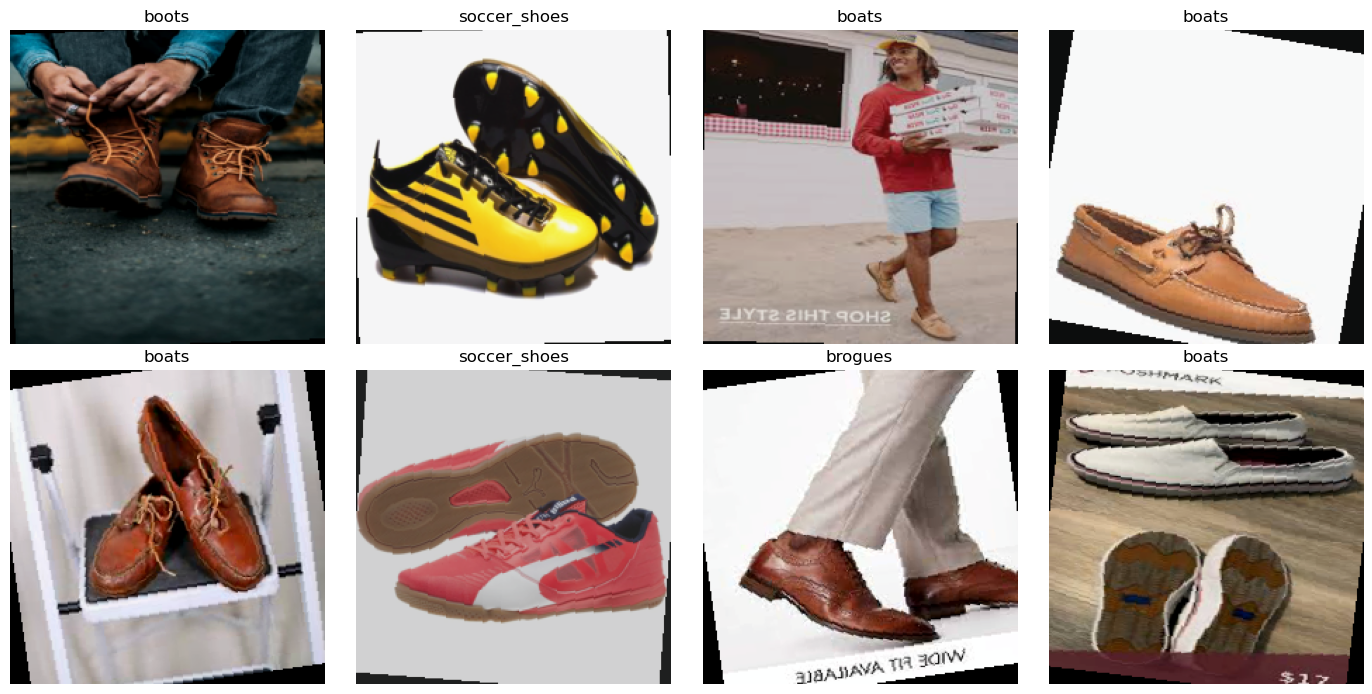

In [10]:
# Get one batch of training images
images, labels = next(iter(train_loader))

# Display sample images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()

    # Reverse normalization for display
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = std * image + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. MODEL DEVELOPMENT USING TRANSFER LEARNING

### 3.1 MobileNetV3 Small Architecture

MobileNetV3 Small is a lightweight convolutional neural network designed for efficient image classification.

Transfer learning is used by loading pretrained ImageNet weights. The original classification layer is replaced with a new output layer containing ten neurons, representing the ten shoe categories.

Initially, the pretrained feature extraction layers are frozen so that training focuses on learning the new shoe classification task.


In [11]:
# Load pretrained MobileNetV3 Small
weights = models.MobileNet_V3_Small_Weights.DEFAULT

model = models.mobilenet_v3_small(weights=weights)

# Freeze pretrained feature extraction layers
for param in model.features.parameters():
    param.requires_grad = False

# Get input features of the original classifier
input_features = model.classifier[3].in_features

# Replace final classification layer
model.classifier[3] = nn.Linear(input_features, num_classes)

# Initialize the new classification layer
nn.init.kaiming_normal_(
    model.classifier[3].weight,
    mode="fan_in",
    nonlinearity="relu"
)

nn.init.zeros_(model.classifier[3].bias)

# Move model to computing device
model = model.to(device)

print("MobileNetV3 Small loaded successfully!")
print("Number of output classes:", num_classes)
print("Computing device:", device)

MobileNetV3 Small loaded successfully!
Number of output classes: 10
Computing device: cuda


### 3.2 Loss Function and Optimization

Cross-Entropy Loss is selected because this is a multi-class classification problem.

The Adam optimizer updates the model parameters to minimize classification error. A learning rate of 0.001 is initially used for training the newly added classification layer.

Weight decay is included as an L2 regularization technique to discourage excessively large model weights and help reduce overfitting.


In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


### 3.3 Training the Neural Network

The model is trained using mini-batch gradient descent for ten epochs.

During each epoch, the training images pass through the network, predictions are compared with their actual labels using Cross-Entropy Loss, and gradients are calculated through backpropagation.

The Adam optimizer updates the trainable parameters. Training loss, validation loss and validation accuracy are recorded to monitor learning and detect overfitting.


In [13]:
EPOCHS = 10

train_losses = []
val_losses = []
val_accuracies = []

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)

    # Validation phase
    model.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / len(val_dataset)
    epoch_val_accuracy = 100 * correct / total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    # Save best model
    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = epoch_val_accuracy

        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

print("\nTraining completed! - shoe_classifier.ipynb:81")
print(f"Best validation accuracy: {best_val_accuracy:.2f}% - shoe_classifier.ipynb:82")

# Restore best model
model.load_state_dict(best_model_weights)

Epoch [1/10] Train Loss: 1.5514 Val Loss: 1.2671 Val Accuracy: 57.57%
Epoch [2/10] Train Loss: 1.0897 Val Loss: 0.9934 Val Accuracy: 67.95%
Epoch [3/10] Train Loss: 0.9357 Val Loss: 0.9752 Val Accuracy: 68.10%
Epoch [4/10] Train Loss: 0.8210 Val Loss: 1.0409 Val Accuracy: 65.43%
Epoch [5/10] Train Loss: 0.7645 Val Loss: 0.9976 Val Accuracy: 66.32%
Epoch [6/10] Train Loss: 0.6732 Val Loss: 0.9290 Val Accuracy: 69.58%
Epoch [7/10] Train Loss: 0.6250 Val Loss: 0.9302 Val Accuracy: 68.40%
Epoch [8/10] Train Loss: 0.5794 Val Loss: 0.9159 Val Accuracy: 72.11%
Epoch [9/10] Train Loss: 0.5037 Val Loss: 1.0053 Val Accuracy: 68.10%
Epoch [10/10] Train Loss: 0.5058 Val Loss: 0.9536 Val Accuracy: 69.88%

Training completed! - shoe_classifier.ipynb:81
Best validation accuracy: 72.11% - shoe_classifier.ipynb:82


<All keys matched successfully>

### 3.4 Training and Validation Performance

Training and validation loss curves are plotted to evaluate the learning behaviour of the neural network.

A decreasing training loss indicates that the model is learning from the training dataset. Validation loss helps determine whether the learned patterns generalize to unseen images.

A large or increasing gap between training and validation loss may indicate overfitting.


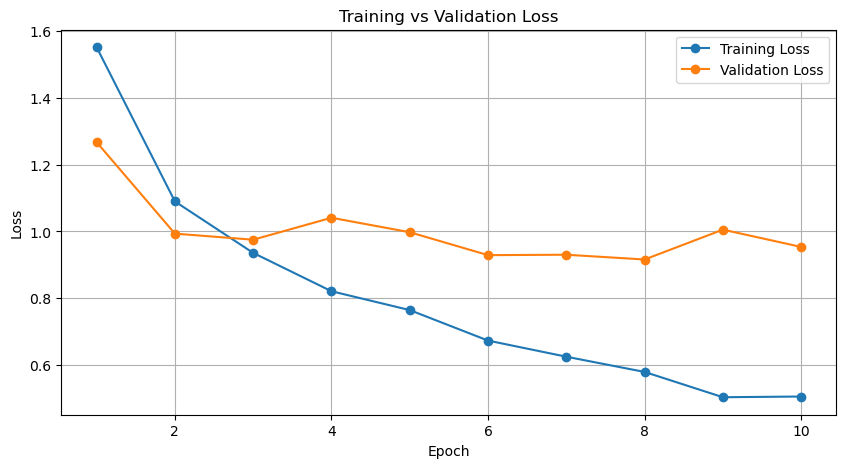

In [14]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_losses, marker="o", label="Training Loss")
plt.plot(epochs_range, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

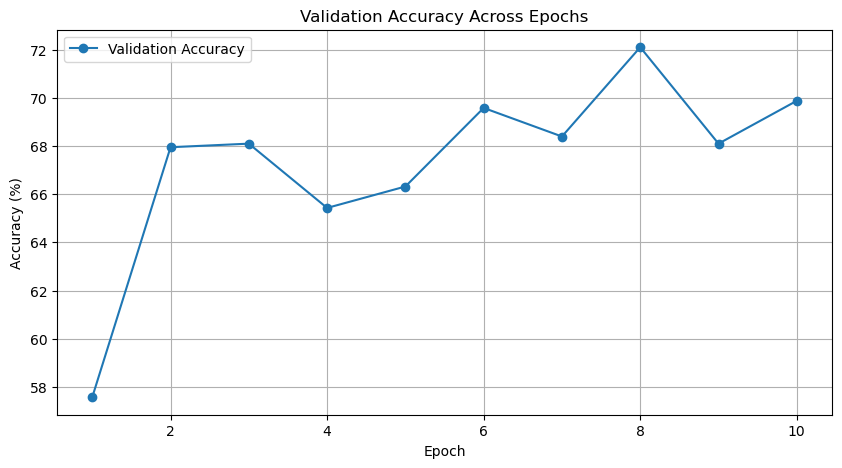

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Validation Accuracy Across Epochs")
plt.legend()
plt.grid(True)

plt.show()

## 4. FINE-TUNING THE NEURAL NETWORK

### 4.1 Fine-Tuning Pretrained Layers

Fine-tuning involves unfreezing selected pretrained layers and allowing them to adapt to the shoe classification dataset.

In this experiment, the final three feature-extraction blocks of MobileNetV3 Small are unfrozen. Earlier layers remain frozen to preserve the general visual features learned from ImageNet.

A smaller learning rate is used for the pretrained layers to prevent large changes to their previously learned weights. The newly added classification layers use a slightly higher learning rate.

Validation performance is monitored to determine whether fine-tuning improves generalization and reduces classification error.


In [16]:
# Unfreeze the final three feature extraction blocks

for param in model.features[-3:].parameters():
    param.requires_grad = True

# Count trainable and frozen parameters

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

frozen_parameters = sum(
    p.numel() for p in model.parameters() if not p.requires_grad
)

print("Fine-tuning configuration:")
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", frozen_parameters)

Fine-tuning configuration:
Trainable parameters: 1245738
Frozen parameters: 282368


In [17]:
# Separate parameter groups

optimizer = optim.Adam(
    [
        {
            "params": model.features[-3:].parameters(),
            "lr": 0.00001
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.0001
        }
    ],
    weight_decay=0.0001
)

print("Finetuning optimizer configured successfully! - shoe_classifier.ipynb:17")

Finetuning optimizer configured successfully! - shoe_classifier.ipynb:17


In [18]:
FINE_TUNE_EPOCHS = 8
PATIENCE = 3

fine_train_losses = []
fine_val_losses = []
fine_val_accuracies = []

best_fine_val_loss = float("inf")
best_fine_val_accuracy = 0.0

best_fine_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

for epoch in range(FINE_TUNE_EPOCHS):

    # Training phase
    model.train()

    # Keep earlier frozen feature blocks in evaluation mode
    for layer in model.features[:-3]:
        layer.eval()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)

    # Validation phase
    model.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / len(val_dataset)
    epoch_val_accuracy = 100 * correct / total

    fine_train_losses.append(epoch_train_loss)
    fine_val_losses.append(epoch_val_loss)
    fine_val_accuracies.append(epoch_val_accuracy)

    print(
        f"Fine-tuning Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

    # Save model when validation loss improves
    if epoch_val_loss < best_fine_val_loss:

        best_fine_val_loss = epoch_val_loss
        best_fine_val_accuracy = epoch_val_accuracy

        best_fine_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("Early stopping activated. - shoe_classifier.ipynb:105")

        break

# Restore the best fine-tuned model
model.load_state_dict(best_fine_weights)

print("\nFinetuning completed! - shoe_classifier.ipynb:112")
print(
    f"Best fine-tuned validation accuracy: "
    f"{best_fine_val_accuracy:.2f}%"
)

Fine-tuning Epoch [1/8] Train Loss: 0.4068 Val Loss: 0.8739 Val Accuracy: 72.26%
Fine-tuning Epoch [2/8] Train Loss: 0.3893 Val Loss: 0.8585 Val Accuracy: 72.11%
Fine-tuning Epoch [3/8] Train Loss: 0.3660 Val Loss: 0.8545 Val Accuracy: 72.85%
Fine-tuning Epoch [4/8] Train Loss: 0.3450 Val Loss: 0.8573 Val Accuracy: 73.74%
Fine-tuning Epoch [5/8] Train Loss: 0.3228 Val Loss: 0.8549 Val Accuracy: 73.00%
Fine-tuning Epoch [6/8] Train Loss: 0.3263 Val Loss: 0.8511 Val Accuracy: 73.59%
Fine-tuning Epoch [7/8] Train Loss: 0.3097 Val Loss: 0.8440 Val Accuracy: 74.33%
Fine-tuning Epoch [8/8] Train Loss: 0.2973 Val Loss: 0.8513 Val Accuracy: 74.04%

Finetuning completed! - shoe_classifier.ipynb:112
Best fine-tuned validation accuracy: 74.33%


### 4.2 Comparison of Baseline and Fine-Tuned Models

The baseline model and fine-tuned model are compared using their best validation accuracies.

This experiment determines whether allowing selected pretrained layers to adapt to the shoe dataset improves classification performance.

The validation results are used to assess generalization rather than relying solely on training accuracy.


In [19]:
baseline_accuracy = best_val_accuracy

print("MODEL PERFORMANCE COMPARISON")
print("-" * 40)

print(f"Baseline accuracy:     {baseline_accuracy:.2f}%")
print(f"Fine-tuned accuracy:   {best_fine_val_accuracy:.2f}%")

improvement = best_fine_val_accuracy - baseline_accuracy

print(f"Accuracy improvement:  {improvement:+.2f} percentage points")

MODEL PERFORMANCE COMPARISON
----------------------------------------
Baseline accuracy:     72.11%
Fine-tuned accuracy:   74.33%
Accuracy improvement:  +2.23 percentage points


## 5. MODEL CHECKPOINTING AND STORAGE

The best-performing fine-tuned model is saved using PyTorch's state dictionary functionality.

Saving the model allows it to be loaded later for inference without repeating the training process. This is particularly useful when deploying the classifier as a real-world shoe recognition application.


In [20]:
import os

# Create results directory
results_path = "./results"
os.makedirs(results_path, exist_ok=True)

# Save model parameters
model_save_path = os.path.join(
    results_path,
    "shoe_classifier_mobilenetv3.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "image_size": IMAGE_SIZE
}, model_save_path)

print("Model saved successfully!")
print("Location:", model_save_path)

Model saved successfully!
Location: ./results\shoe_classifier_mobilenetv3.pth


## 6. FINAL MODEL EVALUATION

The trained model is evaluated using the independent testing dataset.

The test dataset contains images that were excluded from the training and validation processes. This provides an estimate of how well the model generalizes to previously unseen shoe images.

Test accuracy, precision, recall and F1-score are calculated to assess classification performance across all ten shoe categories.


In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actual.extend(labels.numpy())

# Calculate accuracy
test_accuracy = accuracy_score(
    all_actual,
    all_predictions
)

print("FINAL TEST ACCURACY")
print(f"{test_accuracy * 100:.2f}%")

FINAL TEST ACCURACY
75.22%


In [22]:
print(
    classification_report(
        all_actual,
        all_predictions,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

ballet_flats       0.76      0.73      0.75        90
       boats       0.73      0.73      0.73        90
       boots       0.77      0.53      0.62        38
     brogues       0.82      0.83      0.82        90
       clogs       0.67      0.69      0.68        90
  flip_flops       0.79      0.70      0.74        37
     loafers       0.60      0.70      0.65        37
     sandals       0.75      0.71      0.73        38
    sneakers       0.80      0.83      0.82       127
soccer_shoes       0.77      0.89      0.82        37

    accuracy                           0.75       674
   macro avg       0.75      0.74      0.74       674
weighted avg       0.75      0.75      0.75       674



## 6.1 CONFUSION MATRIX

A confusion matrix is used to examine the classification performance of the model across the ten shoe categories.

The diagonal values represent correctly classified images, while values outside the diagonal represent incorrect predictions.

This helps identify shoe categories that the model finds difficult to distinguish.


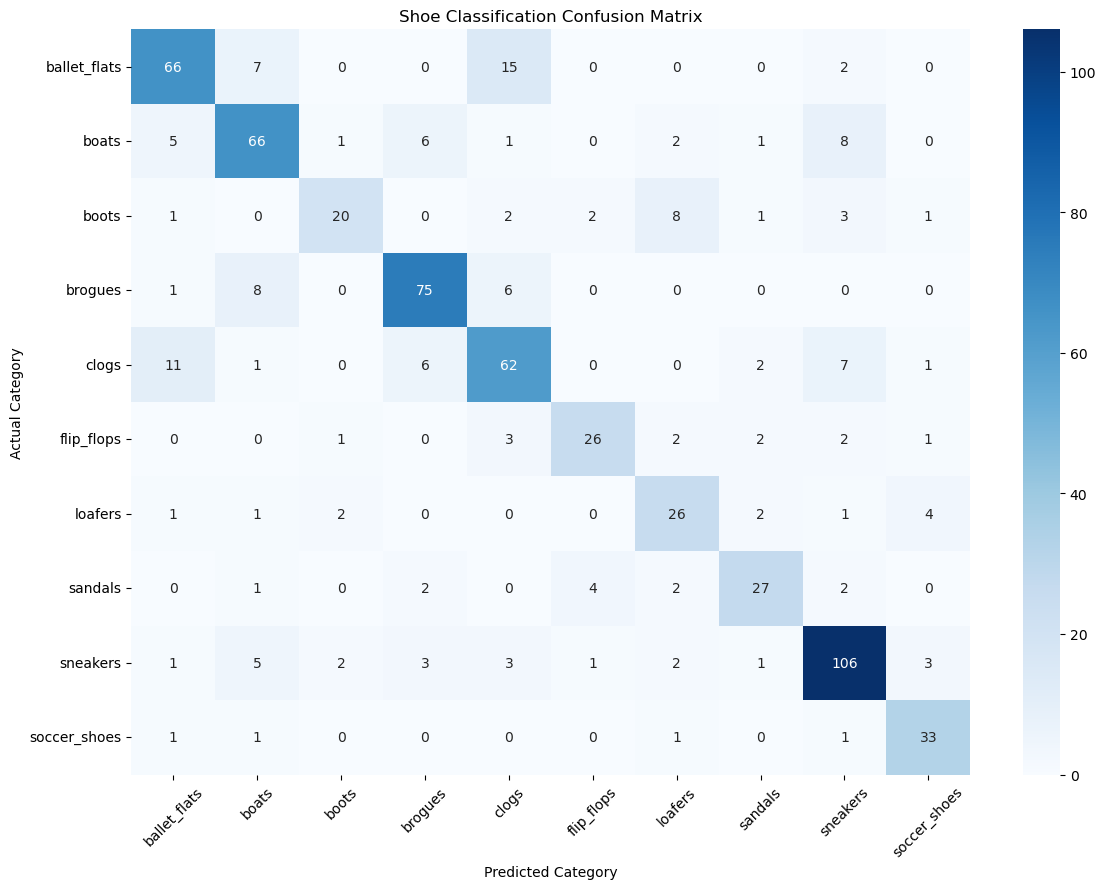

In [23]:
import seaborn as sns

cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Shoe Classification Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## Real-World Shoe Classification with Top-3 Predictions

This section allows the trained MobileNetV3 model to classify shoe photographs supplied by users.

Instead of displaying only the highest prediction, the system displays the three most likely shoe categories and their confidence scores.

This helps us investigate classification errors, particularly when the model encounters unfamiliar footwear or photographs taken from different angles.

A confidence warning is also included to alert users when the model's highest prediction is relatively uncertain.


In [24]:
from PIL import Image
import torch
import matplotlib.pyplot as plt

def predict_shoe(image_path):

    # 1. Load the image
    image = Image.open(image_path).convert("RGB")

    # 2. Apply the same preprocessing used during evaluation
    image_tensor = evaluation_transform(image).unsqueeze(0).to(device)

    # 3. Set the model to evaluation mode
    model.eval()

    # 4. Make predictions
    with torch.no_grad():
        outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        # Get the top 3 predictions
        top_probabilities, top_indices = torch.topk(
            probabilities, k=3, dim=1
        )

    # 5. Display the original image
    plt.figure(figsize=(7, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Shoe Image Analysis")
    plt.show()

    # 6. Display classification results
    print("\nSHOE CLASSIFICATION RESULTS - shoe_classifier.ipynb:35")
    print("" * 35)

    for rank in range(3):

        class_index = top_indices[0][rank].item()
        confidence = top_probabilities[0][rank].item() * 100

        predicted_class = class_names[class_index]

        print(
            f"{rank + 1}. {predicted_class}: "
            f"{confidence:.2f}%"
        )

    # 7. Display the main prediction
    highest_confidence = top_probabilities[0][0].item() * 100

    print("\nFINAL PREDICTION - shoe_classifier.ipynb:53")
    print("" * 35)

    print(f"Predicted Shoe: {class_names[top_indices[0][0].item()]} - shoe_classifier.ipynb:56")
    print(f"Confidence: {highest_confidence:.2f}% - shoe_classifier.ipynb:57")

    # 8. Confidence warning
    if highest_confidence < 50:
        print("\nWARNING: Low confidence prediction. - shoe_classifier.ipynb:61")
        print("The model may be uncertain about this Shoe. - shoe_classifier.ipynb:62")

    elif highest_confidence < 70:
        print("\nNOTICE: Moderate confidence prediction. - shoe_classifier.ipynb:65")

    else:
        print("\nThe model produced a relatively strong prediction. - shoe_classifier.ipynb:68")

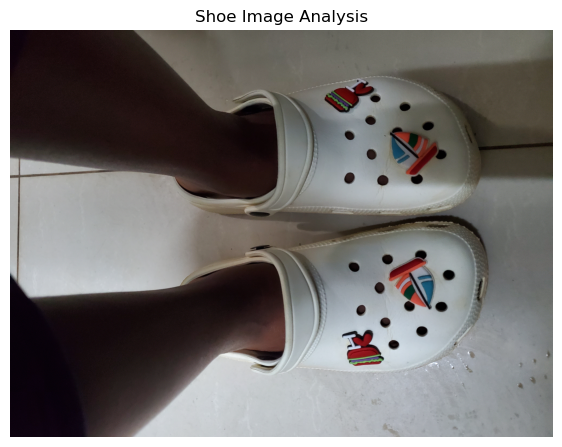


SHOE CLASSIFICATION RESULTS - shoe_classifier.ipynb:35

1. clogs: 75.55%
2. sandals: 20.41%
3. sneakers: 3.71%

FINAL PREDICTION - shoe_classifier.ipynb:53

Predicted Shoe: clogs - shoe_classifier.ipynb:56
Confidence: 75.55% - shoe_classifier.ipynb:57

The model produced a relatively strong prediction. - shoe_classifier.ipynb:68


In [35]:
predict_shoe("./results/my_shoe11.jpg")

In [26]:
import os
import torch

os.makedirs("models", exist_ok=True)

checkpoint_path = "models/shoe_classifier_mobilenetv3.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "image_size": IMAGE_SIZE
}, checkpoint_path)

print("Model saved to: - shoe_classifier.ipynb:15", checkpoint_path)

Model saved to: - shoe_classifier.ipynb:15 models/shoe_classifier_mobilenetv3.pth


In [27]:
checkpoint_path = "models/shoe_classifier_mobilenetv3.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]
num_classes = checkpoint["num_classes"]
IMAGE_SIZE = checkpoint["image_size"]

weights = None
model = models.mobilenet_v3_small(weights=weights)

input_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(input_features, num_classes)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Saved shoe classifier loaded successfully! - shoe_classifier.ipynb:23")
print("Using device: - shoe_classifier.ipynb:24", device)

Saved shoe classifier loaded successfully! - shoe_classifier.ipynb:23
Using device: - shoe_classifier.ipynb:24 cuda


## Final Evaluation on the Test Dataset

The selected MobileNetV3 Small model is evaluated using a held-out test dataset that was not used during training or model selection.

The evaluation measures the model's ability to classify unseen shoe images using accuracy, precision, recall and F1-score.

A confusion matrix is also generated to identify which footwear categories are most frequently confused.

The test set is evaluated after the training and model-selection process is complete to provide an unbiased estimate of performance on images from the same dataset source.


In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
import torch

model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actual.extend(labels.numpy())

test_accuracy = accuracy_score(all_actual, all_predictions)

print("FINAL TEST RESULTS")
print("-" * 40)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Correct predictions: {sum(np.array(all_predictions) == np.array(all_actual))}")
print(f"Total test images: {len(all_actual)}")

FINAL TEST RESULTS
----------------------------------------
Test accuracy: 75.22%
Correct predictions: 507
Total test images: 674


In [30]:
report = classification_report(
    all_actual,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
)

print("CLASSIFICATION REPORT - shoe_classifier.ipynb:9")
print("" * 60)
print(report)

CLASSIFICATION REPORT - shoe_classifier.ipynb:9

              precision    recall  f1-score   support

ballet_flats       0.76      0.73      0.75        90
       boats       0.73      0.73      0.73        90
       boots       0.77      0.53      0.62        38
     brogues       0.82      0.83      0.82        90
       clogs       0.67      0.69      0.68        90
  flip_flops       0.79      0.70      0.74        37
     loafers       0.60      0.70      0.65        37
     sandals       0.75      0.71      0.73        38
    sneakers       0.80      0.83      0.82       127
soccer_shoes       0.77      0.89      0.82        37

    accuracy                           0.75       674
   macro avg       0.75      0.74      0.74       674
weighted avg       0.75      0.75      0.75       674



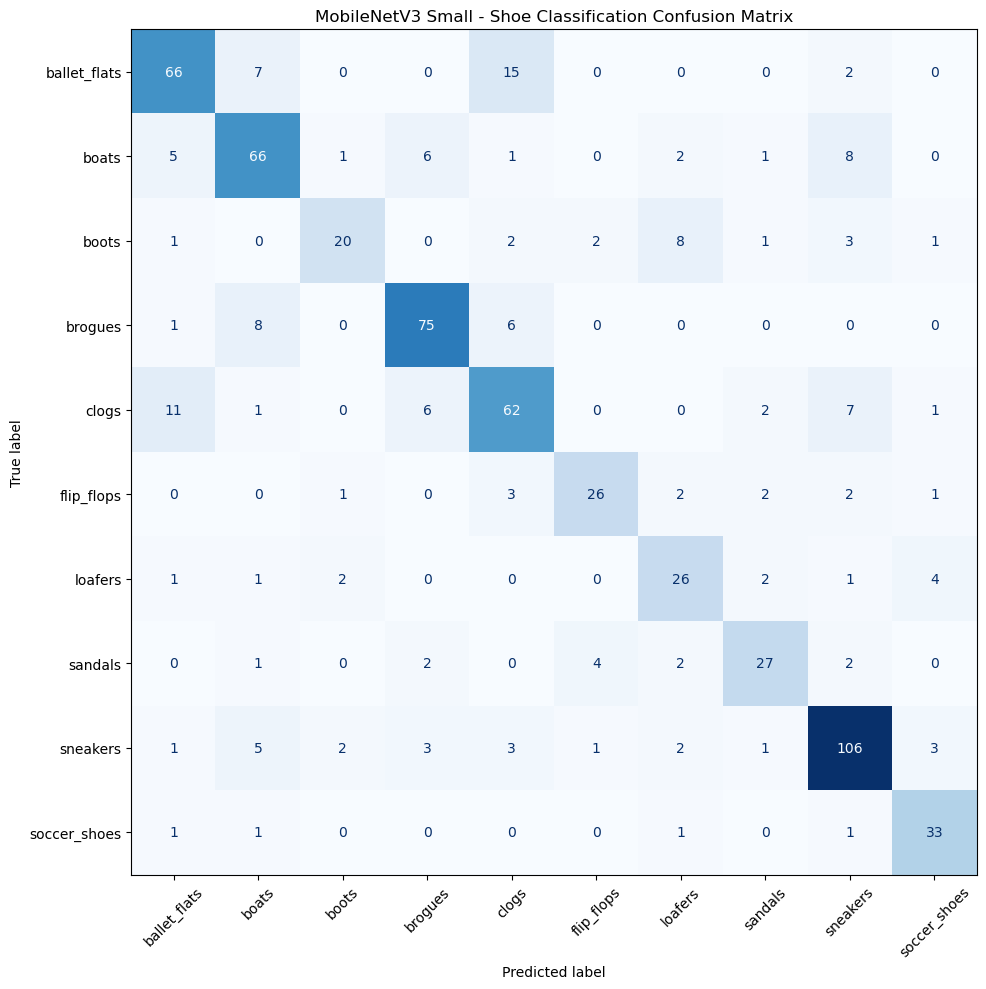

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("MobileNetV3 Small - Shoe Classification Confusion Matrix")
plt.tight_layout()
plt.show()

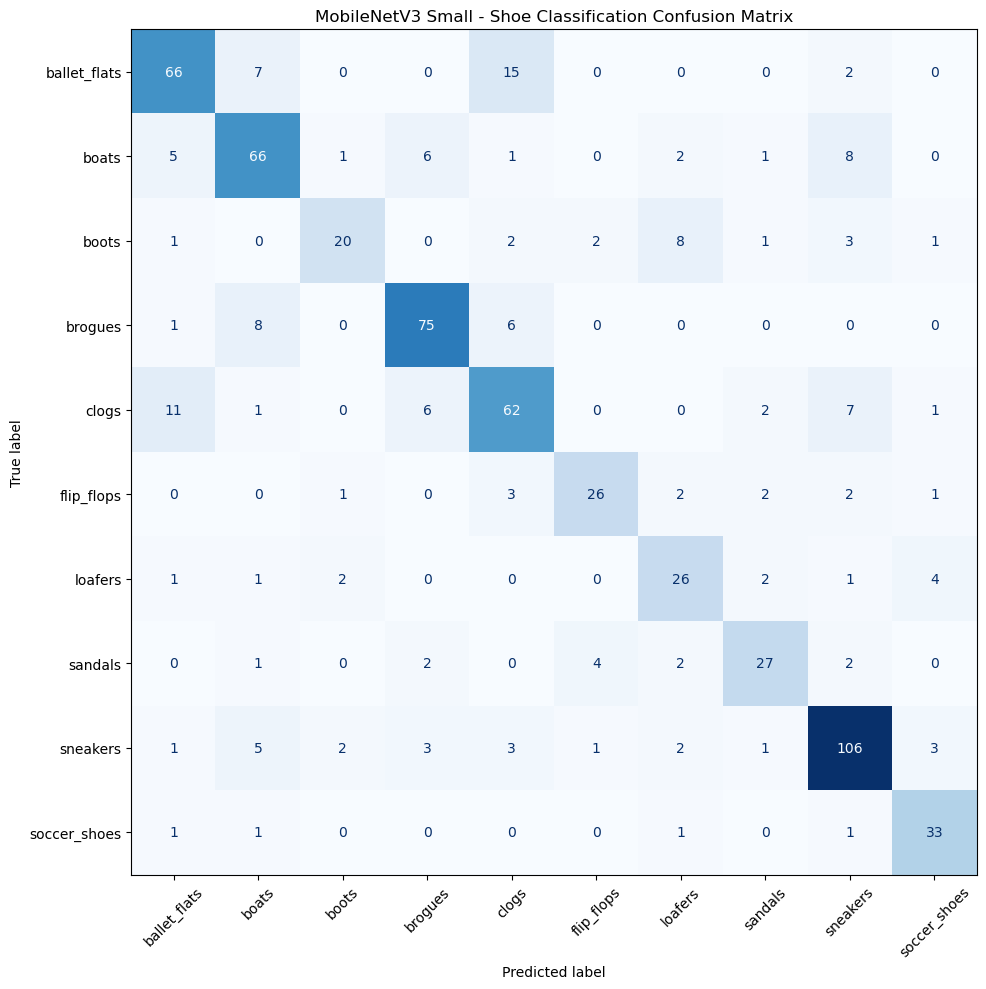

Evaluation results saved in the results folder. - shoe_classifier.ipynb:32


In [32]:
import os
import pandas as pd

os.makedirs("results", exist_ok=True)

# Save classification report
with open("results/classification_report.txt", "w") as file:
    file.write(f"Test Accuracy: {test_accuracy * 100:.2f}%\n\n")
    file.write(report)

# Save confusion matrix image
fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("MobileNetV3 Small - Shoe Classification Confusion Matrix")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Evaluation results saved in the results folder. - shoe_classifier.ipynb:32")

## Test Evaluation Results and Discussion

The fine-tuned MobileNetV3 Small model achieved a test accuracy of **75.22%**, correctly classifying 507 out of 674 test images.

The model obtained a macro F1-score of 0.74 and a weighted F1-score of 0.75, indicating moderate and reasonably balanced performance across the ten footwear categories.

Brogues, sneakers and soccer shoes achieved strong F1-scores of 0.82. Soccer shoes had the highest recall at 0.89, indicating that the model identified most of the soccer-shoe images in the test set.

Boots showed the weakest recall at 0.53, while loafers had the lowest precision at 0.60. These results suggest that the model frequently misses boots and may incorrectly classify other footwear as loafers. Clogs also showed room for improvement, with an F1-score of 0.68.

### Conclusion

The results demonstrate that transfer learning and fine-tuning enabled the model to learn useful visual features for shoe classification. However, performance varies across categories, and the real-world camera-angle experiments revealed additional viewpoint sensitivity.

Future improvements should focus on examining class-specific errors, increasing training-image diversity and evaluating the model using additional real-world photographs.

The test accuracy represents performance on a held-out split from the same dataset source; it does not guarantee equivalent performance on all real-world footwear.


In [33]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully uninstalled packaging-26.3
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spyder 5.5.1 requires ipython!=8.17.1,<9.0.0,>=8.13.0; python_version > "3.8", but you have ipython 9.17.1 which is incompatible.
spyder 5.5.1 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.1 which is incompatible.
spyder-kernels 2.5.0 requires ipykernel<7,>=6.23.2; python_version >= "3.8", but you have ipykernel 7.4.0 which is incompatible.
spyder-kernels 2.5.0 requires ipython!=8.17.1,<9,>=8.13.0; python_version > "3.8", but you have ipython 9.17.1 which is incompatible.


In [34]:
import sys
import torch

print("Python executable: - shoe_classifier.ipynb:4", sys.executable)
print("PyTorch: - shoe_classifier.ipynb:5", torch.__version__)
print("CUDA available: - shoe_classifier.ipynb:6", torch.cuda.is_available())

Python executable: - shoe_classifier.ipynb:4 c:\ProgramData\anaconda3\python.exe
PyTorch: - shoe_classifier.ipynb:5 2.14.1+cu130
CUDA available: - shoe_classifier.ipynb:6 True
